# Commodity market regimes — Part 1: price-based machine learning
**Ons Jdey & Senghak Rou | ML for Portfolio Management and Trading**

This notebook studies whether months with similar commodity market conditions can be grouped into interpretable regimes. It uses Brent oil, US natural gas, gold, silver and copper. All inputs are included: no API key or internet is needed.

**Scope:** data audit, exploration, causal rolling features, K-Means, Gaussian mixtures, chronological validation, regime interpretation and held-out diagnostics. News sentiment and portfolio optimization are reserved for later parts.

Run all cells from this folder. The explanations are in English to match the course.

In [1]:
from pathlib import Path
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
SEED = 42
BASE = Path.cwd()
if not (BASE / 'data').exists() and (BASE / 'commodity_regimes/data').exists():
    BASE = BASE / 'commodity_regimes'
RESULTS = BASE / 'results'
RESULTS.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.grid': True, 'grid.alpha': 0.2})
def plot_save(name):
    plt.tight_layout()
    plt.savefig(RESULTS / name, dpi=150, bbox_inches='tight')
    plt.show()
print('Working folder:', BASE.name)

Working folder: commodity_regimes


## 1. Source and data audit
The original World Bank workbook is preserved in `data/raw`. The cleaned CSV contains monthly average benchmark prices, not month-end executable prices. Different units are retained; comparisons use percentage changes or rebased prices.

We freeze the study at December 2025 so it uses complete calendar years. The downloaded workbook also includes later observations, retained separately. The current snapshot may contain historical revisions. A real-time backtest would additionally need publication dates and vintages.

In [2]:
sources = json.loads((BASE / 'data/sources.json').read_text())
print(json.dumps(sources, indent=2))
prices = pd.read_csv(BASE / 'data/processed/prices_2000_2025.csv', index_col='date', parse_dates=True)
expected = pd.date_range('2000-01-01', '2025-12-01', freq='MS')
audit = pd.DataFrame({'missing': prices.isna().sum(), 'nonpositive': prices.le(0).sum(),
                      'min': prices.min(), 'max': prices.max()})
display(audit)
assert prices.index.is_unique and prices.index.is_monotonic_increasing
assert prices.index.equals(expected), 'Missing or unexpected month'
assert prices.notna().all().all() and prices.gt(0).all().all()
print(f'{len(prices)} months, {prices.shape[1]} commodities. No interpolation or forward filling.')
display(prices.head())

{
  "source": "World Bank Pink Sheet",
  "landing_page": "https://www.worldbank.org/en/research/commodity-markets",
  "download_url": "https://thedocs.worldbank.org/en/doc/74e8be41ceb20fa0da750cda2f6b9e4e-0050012026/related/CMO-Historical-Data-Monthly.xlsx",
  "retrieved_on": "2026-11-07",
  "workbook_update": "Period",
  "sha256": "3c8d9d8dbb48342fdbf24777c39a8ce8964cc2fd0958f72f6779e6e4ad99cde2",
  "frequency": "Monthly average prices; nominal USD",
  "units": {
    "brent": "USD/barrel",
    "natural_gas_us": "USD/MMBtu",
    "gold": "USD/troy oz",
    "silver": "USD/troy oz",
    "copper": "USD/metric ton"
  },
  "study_period": "2000-01 to 2025-12",
  "caveat": "Retrospective revised data, not point-in-time vintages. Monthly average price changes are not tradable total returns."
}
312 months, 5 commodities. No interpolation or forward filling.


,missing,nonpositive,min,max
brent,0,0,18.6,133.90
natural_gas_us,0,0,1.5,13.52
gold,0,0,260.0,4309.00
silver,0,0,4.1,62.30
copper,0,0,1377.0,11785.00


,brent,natural_gas_us,gold,silver,copper
date,,,,,
2000-01-01,25.4,2.42,284,5.2,1844
2000-02-01,27.7,2.65,300,5.2,1801
2000-03-01,27.5,2.79,286,5.1,1739
2000-04-01,22.5,3.03,280,5.1,1679
2000-05-01,27.3,3.58,275,5.0,1786


## 2. Exploratory analysis
A base-100 chart compares proportional price movements. Log changes are additive over time; simple changes are easier to interpret as monthly percentages. Neither is a futures or ETF total return. Natural gas can dominate raw distances, so clustering will require training-only standardization.

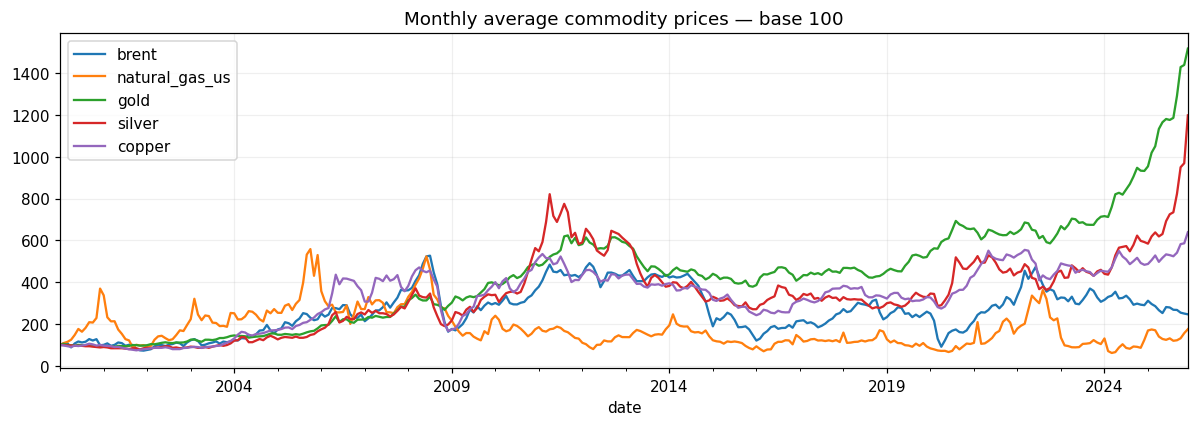

,mean_monthly_change,annualized_vol_proxy,worst_month,best_month
brent,0.0073,0.3174,-0.4000,0.3305
natural_gas_us,0.0136,0.5444,-0.4951,0.8989
gold,0.0094,0.1274,-0.1170,0.1182
silver,0.0103,0.2371,-0.1940,0.3107
copper,0.0078,0.2108,-0.2954,0.2595


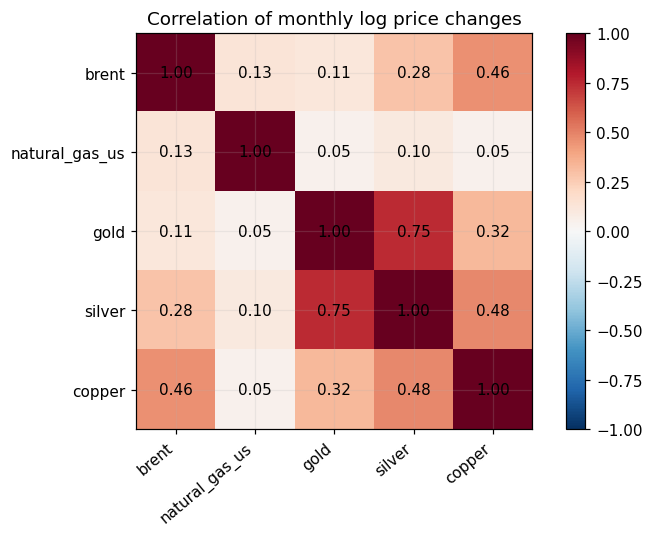

In [3]:
simple_returns = prices.pct_change(fill_method=None).dropna()
log_returns = np.log(prices).diff().dropna()
(prices / prices.iloc[0] * 100).plot(title='Monthly average commodity prices — base 100')
plot_save('01_prices_base100.png')
stats = pd.DataFrame({'mean_monthly_change': simple_returns.mean(),
                      'annualized_vol_proxy': simple_returns.std() * np.sqrt(12),
                      'worst_month': simple_returns.min(), 'best_month': simple_returns.max()})
display(stats.round(4))
fig, ax = plt.subplots(figsize=(7, 5))
corr = log_returns.corr()
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(5), corr.columns, rotation=40, ha='right')
ax.set_yticks(range(5), corr.index)
for i in range(5):
    for j in range(5): ax.text(j, i, f'{corr.iloc[i,j]:.2f}', ha='center', va='center')
fig.colorbar(im, ax=ax)
ax.set_title('Correlation of monthly log price changes')
plot_save('02_correlations.png')

## 3. Features: each observation is a month
We cluster **months**, not the five commodities. At observation month $t$, features use prices up to $t$:

- five one-month log changes $r_{i,t}=\log(P_{i,t}/P_{i,t-1})$;
- five three-month momenta $\sum_{j=0}^{2}r_{i,t-j}$;
- five trailing twelve-month volatilities $\sqrt{12}\,\mathrm{std}(r_{i,t-11},...,r_{i,t})$.

This gives 15 features. Momentum and returns overlap: this is a transparent starting specification, not a unique optimal representation. Warm-up observations are dropped. A detected month-$t$ state becomes usable only once those monthly prices have been published.

In [4]:
features = pd.concat({
    'return_1m': log_returns,
    'momentum_3m': log_returns.rolling(3, min_periods=3).sum(),
    'volatility_12m': log_returns.rolling(12, min_periods=12).std() * np.sqrt(12)
}, axis=1).dropna()
features.columns = ['__'.join(c) for c in features.columns]
assert np.isfinite(features.to_numpy()).all()
features.to_csv(BASE / 'data/processed/features.csv')
print('Feature matrix:', features.shape, '| Each row = one month')
display(features.head())

Feature matrix: (300, 15) | Each row = one month


,return_1m__brent,return_1m__natural_gas_us,return_1m__gold,return_1m__silver,return_1m__copper,momentum_3m__brent,momentum_3m__natural_gas_us,momentum_3m__gold,momentum_3m__silver,momentum_3m__copper,volatility_12m__brent,volatility_12m__natural_gas_us,volatility_12m__gold,volatility_12m__silver,volatility_12m__copper
date,,,,,,,,,,,,,,,
2001-01-01,0.019725,-0.091185,-0.022389,0.021506,-0.034628,-0.188164,0.487039,-0.018692,-0.021053,-0.060230,0.440941,0.508882,0.101880,0.048080,0.140259
2001-02-01,0.067951,-0.372359,-0.011385,-0.021506,-0.012381,-0.170697,0.014312,-0.015152,-0.021506,-0.016288,0.437337,0.695832,0.077538,0.048774,0.138867
2001-03-01,-0.115960,-0.087173,0.003810,-0.044452,-0.015407,-0.028285,-0.550717,-0.029965,-0.044452,-0.062416,0.452312,0.711919,0.067565,0.059230,0.135053
2001-04-01,0.048009,0.001936,-0.011472,0.000000,-0.044086,0.000000,-0.457596,-0.019048,-0.065958,-0.071873,0.403679,0.712617,0.066014,0.059230,0.137867
2001-05-01,0.107312,-0.205410,0.045120,0.000000,0.010759,0.039361,-0.290647,0.037458,-0.044452,-0.048734,0.368882,0.739639,0.081933,0.059802,0.121037


## 4. Chronological split
Training ends in 2015, validation covers 2016–2020, and the untouched test covers 2021–2025. Earlier feature windows are allowed for later observations because they are already historical. The scaler sees training data only.

For K-Means, choose $k$ using validation silhouette, with candidate values 2–4. Silhouette measures geometric separation, not predictability or investment value. Small monthly samples warrant a compact model.

In [5]:
train = features.loc[:'2015']
valid = features.loc['2016':'2020']
test = features.loc['2021':'2025']
assert train.index.max() < valid.index.min() < test.index.min()
scaler = StandardScaler().fit(train)
Z_train, Z_valid, Z_test = [scaler.transform(d) for d in [train, valid, test]]
display(pd.DataFrame({'months': [len(train), len(valid), len(test)],
                      'start': [d.index.min() for d in [train,valid,test]],
                      'end': [d.index.max() for d in [train,valid,test]]},
                     index=['train','validation','test']))
rows, km_candidates = [], {}
for k in [2, 3, 4]:
    model = KMeans(n_clusters=k, n_init=30, random_state=SEED).fit(Z_train)
    pred = model.predict(Z_valid)
    score = silhouette_score(Z_valid, pred) if 1 < len(np.unique(pred)) < len(pred) else np.nan
    rows.append({'k': k, 'train_inertia': model.inertia_, 'validation_silhouette': score,
                 'validation_clusters_observed': len(np.unique(pred))})
    km_candidates[k] = model
selection = pd.DataFrame(rows).set_index('k')
display(selection)
if selection.validation_silhouette.notna().any():
    best_k = int(selection.validation_silhouette.idxmax())
else:
    best_k = 2
    warnings.warn('Validation has insufficient clusters: fallback k=2; do not claim validation support.')
print('Selected K-Means k:', best_k)

Selected K-Means k: 3


,months,start,end
train,180,2001-01-01,2015-12-01
validation,60,2016-01-01,2020-12-01
test,60,2021-01-01,2025-12-01


,train_inertia,validation_silhouette,validation_clusters_observed
k,,,
2,2257.263743,0.096434,2
3,2008.028651,0.114672,3
4,1786.796133,0.092386,4


## 5. Gaussian mixture benchmark
K-Means assigns hard groups around centroids. A GMM gives probabilities and allows different variances. We restrict it to diagonal covariances to limit parameters. Choose the number of components by training BIC; lower is better. This criterion differs from K-Means validation silhouette, so there is no single cross-model winner from these scores.

In [6]:
gmm_rows = []
for k in [2, 3, 4]:
    model = GaussianMixture(n_components=k, covariance_type='diag', reg_covar=1e-4,
                            n_init=10, max_iter=500, random_state=SEED).fit(Z_train)
    gmm_rows.append({'k': k, 'train_BIC': model.bic(Z_train),
                     'validation_loglik_per_month': model.score(Z_valid),
                     'converged': model.converged_})
gmm_selection = pd.DataFrame(gmm_rows).set_index('k')
display(gmm_selection)
best_gmm_k = int(gmm_selection.train_BIC.idxmin())
print('Selected GMM components:', best_gmm_k)

Selected GMM components: 4


,train_BIC,validation_loglik_per_month,converged
k,,,
2,7355.646060,-20.044954,True
3,7124.531743,-19.900037,True
4,6966.844745,-21.370694,True


## 6. Refit once, then evaluate the held-out period
After choosing the settings, fit both models and a new scaler on 2001–2020 (all available training and validation feature rows). Test observations never enter model fitting. We keep this model frozen over 2021–2025.

The in-sample labels below are retrospective descriptions. Only test labels are held-out predictions. Numeric labels have no inherent economic meaning and K-Means label 0 need not correspond to GMM label 0.

In [7]:
development = pd.concat([train, valid])
final_scaler = StandardScaler().fit(development)
Z_dev = final_scaler.transform(development)
Z_all = final_scaler.transform(features)
Z_holdout = final_scaler.transform(test)
km = KMeans(n_clusters=best_k, n_init=50, random_state=SEED).fit(Z_dev)
gmm = GaussianMixture(n_components=best_gmm_k, covariance_type='diag', reg_covar=1e-4,
                      n_init=20, max_iter=500, random_state=SEED).fit(Z_dev)
labels = pd.DataFrame({'kmeans': km.predict(Z_all), 'gmm': gmm.predict(Z_all)}, index=features.index)
labels['sample'] = np.where(labels.index <= development.index.max(), 'development', 'test')
probs = pd.DataFrame(gmm.predict_proba(Z_all), index=features.index,
                     columns=[f'gmm_probability_{i}' for i in range(best_gmm_k)])
labels = labels.join(probs)
labels.to_csv(RESULTS / 'regime_labels.csv')
comparison = []
for name in ['kmeans', 'gmm']:
    y = labels.loc[test.index, name]
    sil = silhouette_score(Z_holdout, y) if 1 < y.nunique() < len(y) else np.nan
    comparison.append({'model': name, 'test_silhouette': sil, 'test_regimes_observed': y.nunique()})
display(pd.DataFrame(comparison).set_index('model'))
print('Held-out adjusted Rand agreement:', round(adjusted_rand_score(
    labels.loc[test.index, 'kmeans'], labels.loc[test.index, 'gmm']), 3))
print('GMM refit converged:', gmm.converged_)

Held-out adjusted Rand agreement: 0.211
GMM refit converged: True


,test_silhouette,test_regimes_observed
model,,
kmeans,0.129924,3
gmm,0.007174,4


## 7. Economic interpretation from development data only
Inspect the average market movement, average trailing volatility and cross-asset dispersion in each regime. These profiles summarize conditions, not causal explanations. The labels should be described as relative low/high volatility or positive/negative trend only when the table supports it. We do not assign crisis names by looking at the test period.

mean_commodity_log_change        ... cross_asset_dispersion      
                            mean count  ...                   mean count
kmeans                                  ...                             
0                         0.0450    56  ...                 0.0788    56
1                        -0.0737    29  ...                 0.0892    29
2                         0.0033   155  ...                 0.0599   155

[3 rows x 6 columns]

,regime_0,regime_1,regime_2
return_1m__brent,0.0493,-0.1490,0.0145
return_1m__natural_gas_us,0.0115,-0.0438,-0.0041
return_1m__gold,0.0379,-0.0273,0.0038
return_1m__silver,0.0727,-0.0708,-0.0021
return_1m__copper,0.0535,-0.0775,0.0044
momentum_3m__brent,0.0969,-0.2798,0.0253
momentum_3m__natural_gas_us,0.0034,-0.1206,0.0031
momentum_3m__gold,0.0815,-0.0493,0.0174
momentum_3m__silver,0.1522,-0.1522,0.0054
momentum_3m__copper,0.1136,-0.1540,0.0140


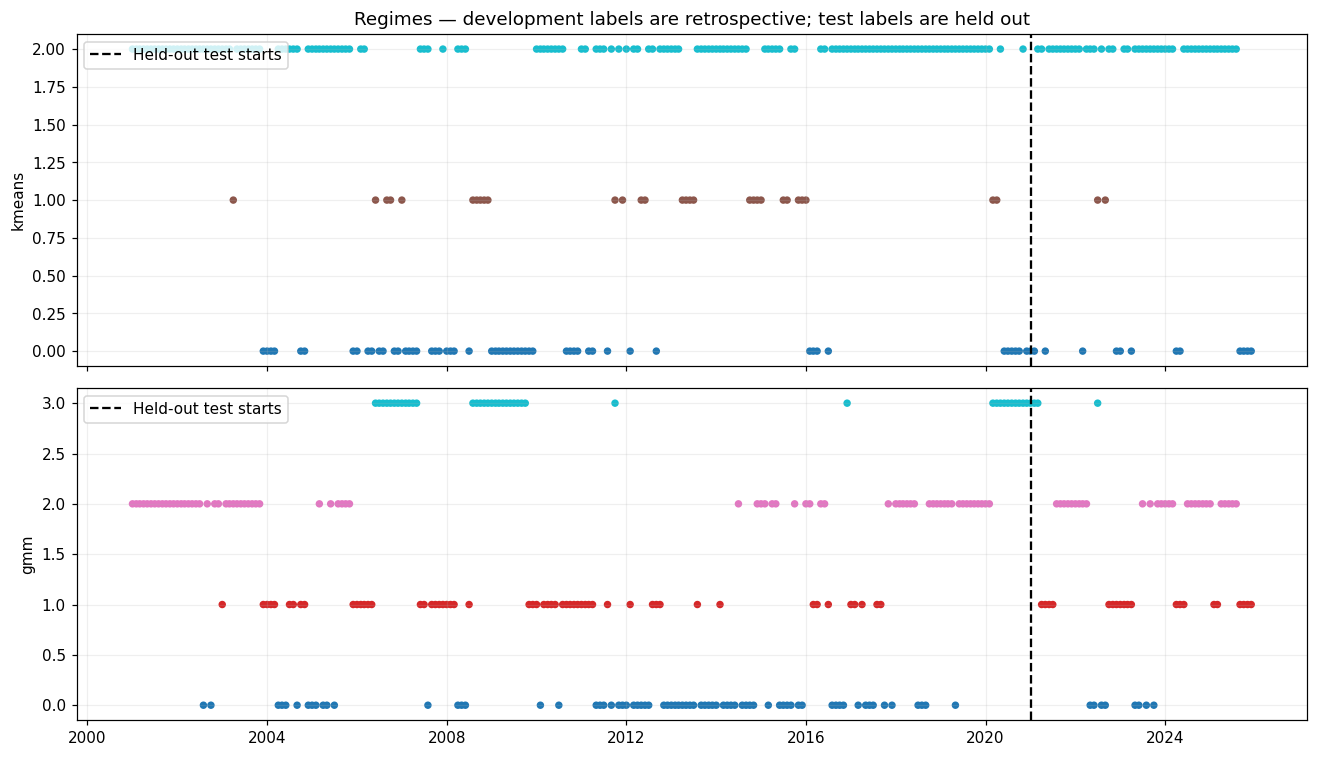

In [8]:
context = pd.DataFrame({
    'mean_commodity_log_change': log_returns.mean(axis=1),
    'mean_trailing_vol': features.filter(like='volatility_12m__').mean(axis=1),
    'cross_asset_dispersion': log_returns.std(axis=1)
}).reindex(features.index)
profile = context.loc[development.index].join(labels['kmeans']).groupby('kmeans').agg(['mean','count'])
display(profile.round(4))
profile.to_csv(RESULTS / 'development_regime_profiles.csv')
centers = pd.DataFrame(final_scaler.inverse_transform(km.cluster_centers_),
                       columns=features.columns).T
centers.columns = [f'regime_{i}' for i in centers.columns]
display(centers.round(4))
centers.to_csv(RESULTS / 'kmeans_centroids_original_units.csv')
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for ax, name in zip(axes, ['kmeans','gmm']):
    ax.scatter(labels.index, labels[name], c=labels[name], cmap='tab10', s=15)
    ax.axvline(pd.Timestamp('2021-01-01'), color='black', linestyle='--', label='Held-out test starts')
    ax.set_ylabel(name); ax.legend(loc='upper left')
axes[0].set_title('Regimes — development labels are retrospective; test labels are held out')
plot_save('03_regime_timeline.png')

## 8. Visualize separation with PCA
PCA is fitted on the development features only, solely to project the 15-dimensional space to two dimensions for visualization. Clustering was performed in all 15 dimensions. A two-dimensional overlap does not prove that the full-space model fails.

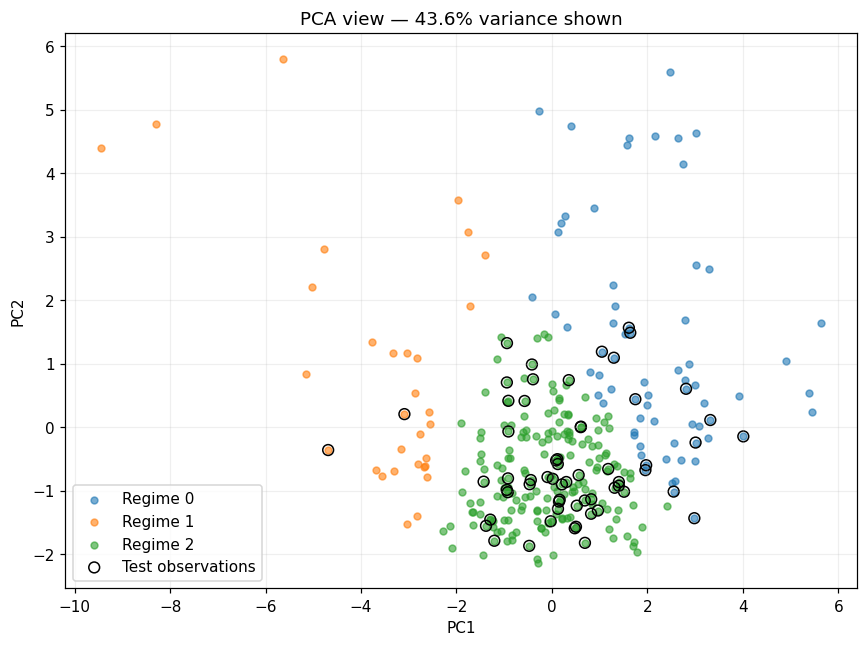

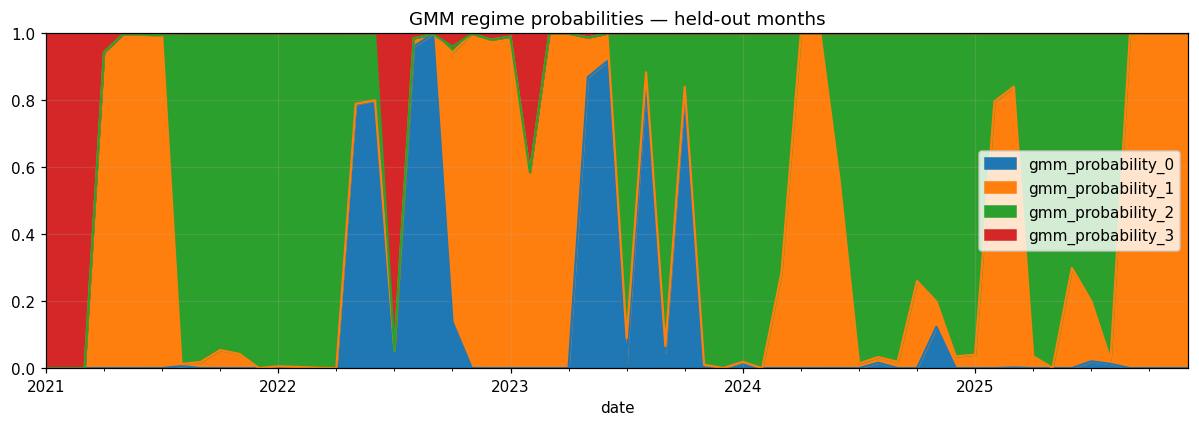

In [9]:
pca = PCA(n_components=2).fit(Z_dev)
projection = pca.transform(Z_all)
fig, ax = plt.subplots(figsize=(8, 6))
for regime in range(best_k):
    mask = labels.kmeans.eq(regime)
    ax.scatter(projection[mask,0], projection[mask,1], label=f'Regime {regime}', alpha=.6, s=20)
test_mask = labels['sample'].eq('test')
ax.scatter(projection[test_mask,0], projection[test_mask,1], facecolors='none',
           edgecolors='black', s=50, label='Test observations')
ax.set(xlabel='PC1', ylabel='PC2', title=f'PCA view — {pca.explained_variance_ratio_.sum():.1%} variance shown')
ax.legend()
plot_save('04_pca_regimes.png')
probs.loc[test.index].plot.area(title='GMM regime probabilities — held-out months', ylim=(0,1))
plot_save('05_gmm_probabilities_test.png')

## 9. Persistence and stability diagnostics
The transition table counts adjacent held-out labels. It describes the observed sequence; K-Means and GMM do not explicitly model transitions. The seed check uses adjusted Rand index (ARI), which is invariant to permutation of regime IDs. High seed agreement measures numerical stability, not economic usefulness.

In [10]:
test_states = labels.loc[test.index, 'kmeans']
transitions = pd.crosstab(test_states.shift(1), test_states).reindex(
    index=range(best_k), columns=range(best_k), fill_value=0).fillna(0)
transition_probabilities = transitions.div(transitions.sum(axis=1).replace(0,np.nan), axis=0)
display(transition_probabilities)
transition_probabilities.to_csv(RESULTS / 'test_transition_probabilities.csv')
print('Held-out state counts:')
display(test_states.value_counts().sort_index().rename('months').to_frame())
print('Held-out fraction of consecutive months keeping same state:',
      round(test_states.iloc[1:].eq(test_states.shift(1).iloc[1:]).mean(),3))
stability=[]
for seed in [0, 7, 21, 99]:
    alt = KMeans(n_clusters=best_k, n_init=30, random_state=seed).fit(Z_dev)
    stability.append({'seed': seed, 'test_ARI_vs_main': adjusted_rand_score(test_states, alt.predict(Z_holdout))})
display(pd.DataFrame(stability))

Held-out state counts:
Held-out fraction of consecutive months keeping same state: 0.729


kmeans,0,1,2
kmeans,,,
0,0.500000,0.000000,0.500000
1,0.000000,0.000000,1.000000
2,0.133333,0.044444,0.822222


,months
kmeans,
0,13
1,2
2,45


,seed,test_ARI_vs_main
0,0,0.932133
1,7,0.799979
2,21,1.000000
3,99,1.000000


## 10. Exploratory forward-price diagnostics — not a trading backtest
Separate contemporaneous regime characteristics from next-month changes. The table below groups the following month's price change by the current held-out state. It is an exploratory test diagnostic, not a parameter-selection criterion or proof of profitable predictability.

**Timing limitation:** the current monthly average may only be published during the following month. Therefore these next-month averages may partially precede signal availability. A tradable strategy needs actual publication timestamps, executable prices and a sufficient lag, as well as roll returns, collateral and transaction costs. No performance claim is made here.

In [11]:
forward = simple_returns.shift(-1).reindex(test.index)
diagnostic = forward.join(test_states.rename('regime')).groupby('regime').mean()
counts = forward.join(test_states.rename('regime')).groupby('regime').count()
display(diagnostic.round(4))
print('Number of available forward observations per asset and regime:')
display(counts)
diagnostic.to_csv(RESULTS / 'exploratory_next_month_price_changes.csv')
# Do not infer that an unavailable final forward observation is a zero return.
assert forward.iloc[-1].isna().all()
print('Final month excluded from forward statistics because January 2026 is outside the study sample.')

Number of available forward observations per asset and regime:
Final month excluded from forward statistics because January 2026 is outside the study sample.


,brent,natural_gas_us,gold,silver,copper
regime,,,,,
0,-0.0052,0.0892,0.0083,0.0285,0.0217
1,-0.0312,-0.0325,0.0042,0.0289,0.0228
2,0.0091,0.0184,0.0171,0.0134,0.0034


,brent,natural_gas_us,gold,silver,copper
regime,,,,,
0,12,12,12,12,12
1,2,2,2,2,2
2,45,45,45,45,45


## Observed findings from this execution
K-Means selected **3 regimes**; the GMM selected **4 components**. Based on development profiles, regime **2** has the lowest average trailing volatility and regime **0** the highest. These are relative descriptions within this sample.

During the 60 held-out months, K-Means assigns **13 months to regime 0, 2 to regime 1, and 45 to regime 2**. Regime 1 therefore has very little held-out evidence: do not draw a robust conditional-return conclusion from two observations. Different counts across K-Means and GMM reflect their different model assumptions, not an accuracy ranking. Unsupervised labels have no ground-truth economic regime target here.

These findings support an initial descriptive classification, while further work is needed to test allocation value. Re-running with different data or settings can change these findings.

## 11. How to read the results and continue
- Interpret the development profile and centroid tables first; low silhouette or tiny clusters can indicate weak separation or outlier-driven groups.
- Compare the two models using held-out geometry, occupancy and interpretability; their numeric labels are not directly comparable.
- GMM uncertainty is informative: probabilities near a tie indicate ambiguous states.
- Twelve-month overlapping features can mechanically create persistence. Do not interpret persistence alone as proof of genuine economic regimes.
- With only 60 test months, conditional return estimates can be noisy. This notebook does not establish statistical significance or outperforming allocation.

**Next price-only extension:** choose investable commodity instruments, build equal-weight and risk-based references, and estimate constrained allocations conditional on regimes using past data only. Evaluate walk-forward, with publication lags and costs. Robustness checks should vary feature windows and historical splits without repeatedly tuning on the final test. Sentiment is excluded from this deliverable.

**Course connections:** `05_Data`, `10_Mean_variance_estimators`, `41_Timing_backtest_with_learning` in https://github.com/schampon/skfin/tree/master/nbs. This notebook is standalone and does not require `skfin`.